
<div style="background-color:rgb(100, 110, 220); padding:10px;">

## Day 7: Unsupervised Learning (Clustering and Dimensionality Reduction):

- **Data Preprocessing**
  - **Dimensionality Reduction**
    - Introduction to PCA
    - Use cases of PCA in preprocessing
- **Machine Learning Algorithms**
  - Introduction to Clustering (K-Means, DBSCAN)
- **Implementing K-Means and DBSCAN clustering.
- Model Selection and Evaluation for Unsupervised Learning
- Extra afternoon
    - UMAP and TSNE





### Dataset:  penguins.csv
### libraries: pandas, scikit learn, matplotlib, and seaborn



# 1. Data Preprocessing – Dimensionality Reduction with PCA


- From `Lecture05` we have learned reducing the number of feature helps: Reducing computational complexity, Removing noise and irrelevant features.
Preventing overfitting by simplifying the model.  Dimensionality reduction
## 1. Dimensionality reduction
Dimensionality reduction represents observations using fewer features. It can reduce storage and computation and sometimes remove noise, but can also discard useful signal. Evaluate its effect on the task rather than assuming that fewer dimensions improve prediction.



## Principal Component Analysis (PCA)
PCA finds orthogonal directions that successively explain the greatest remaining variance of the centred training data. The component directions are stored in `components_`; the coordinates of observations in that basis are **scores** returned by `transform`.

Keeping fewer components gives a linear projection. PCA does not use the target, so high variance need not mean high predictive value. Scaling changes what PCA regards as important.

## Use Cases of PCA:
- Data Preprocessing: Before applying machine learning algorithms, PCA can be used to reduce the number of features, which speeds up computation and improves model performance.
- Visualization: PCA reduces high-dimensional data to 2 or 3 principal components, making it easier to visualize complex datasets. While commonly used as a preprocessing technique, PCA can also serve as a standalone unsupervised learning model for tasks such as pattern recognition and anomaly detection.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('../Lecture_data/penguins.csv')
data

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,species
0,-0.909073,0.819349,-1.444400,-0.573025,Adelie
1,-0.835598,0.163907,-1.082147,-0.509474,Adelie
2,-0.688650,0.466419,-0.430091,-1.208528,Adelie
3,-0.872335,1.777301,-0.792344,-0.700125,Adelie
4,-0.945810,0.365582,-1.444400,-0.731901,Adelie
...,...,...,...,...,...
320,0.578782,-1.701579,0.946471,0.920410,Gentoo
321,0.505308,-1.399067,1.018922,0.825084,Gentoo
322,1.166577,-0.693208,1.526076,1.968991,Gentoo
323,0.211411,-1.146975,0.801570,1.269937,Gentoo


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = data.drop(columns=['species'])
y = data.species
                   
X_train, X_test, y_train_raw, y_test_raw = train_test_split(X, y, train_size=0.8, random_state=12)

label_encoder = LabelEncoder().fit(y_train_raw)

y_train = pd.Series(data=label_encoder.transform(y_train_raw),name='species')
y_test = pd.Series(data=label_encoder.transform(y_test_raw), name='species')

#### Visualizing the relationship between features -- colinearity

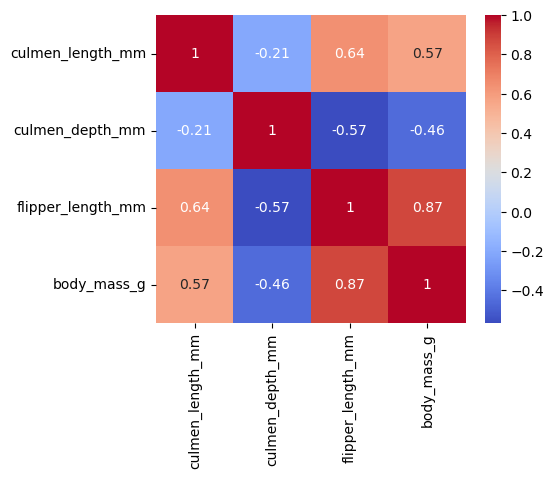

In [3]:
import matplotlib.pyplot as plt
corr = X_train.corr()
fig, ax = plt.subplots(1,1,figsize=(5, 4))
sns.heatmap(corr, cmap='coolwarm',ax=ax, annot=corr);

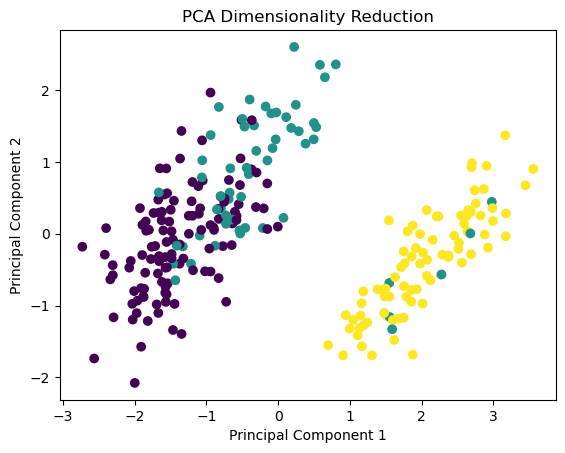

In [4]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Apply PCA to reduce to 
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X_train)

# Plot the reduced data
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Dimensionality Reduction')
plt.show()


### How to Select the Number of Principal Components (k)?
 
 **Choosing 'k'**: <span style = "color:teal">***Trade-off***</span> between compression and performance
 
Explained Variance Ratio:
The explained variance ratio shows how much variance is captured by each principal component.



In [5]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = explained_variance.cumsum()
explained_variance

array([0.6843562 , 0.19162104, 0.09733816, 0.0266846 ])

A **scree plot** visualizes the explained variance of each principal component. Typically, you look for an **elbow point**, where the explained variance starts to level off. This helps you identify the number of components to keep.


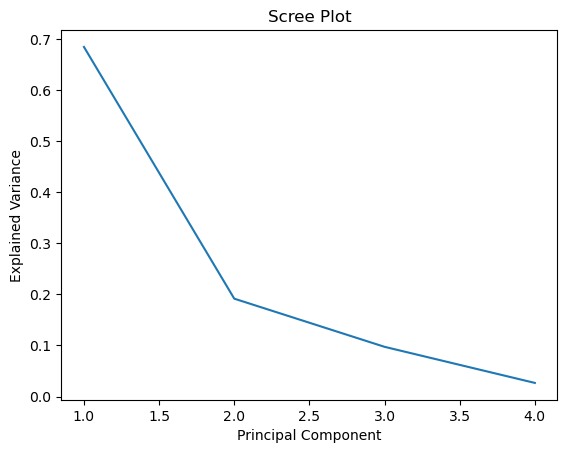

In [6]:
plt.plot(range(1, len(explained_variance) + 1), explained_variance)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance')
plt.title('Scree Plot')
plt.show()


### Kernel PCA for Non-linear Dimensionality Reduction
Instead of working directly on the original data, Kernel PCA computes principal components in a transformed feature space using a kernel function.
Common kernels include: Linear Kernel: Equivalent to standard PCA, Polynomial Kernel: Adds interaction terms to model non-linear relationships, and
Radial Basis Function (RBF) Kernel: Measures similarity between points. Its usefulness depends on feature scales and the kernel parameter; it is not automatically suitable for every non-linear dataset.


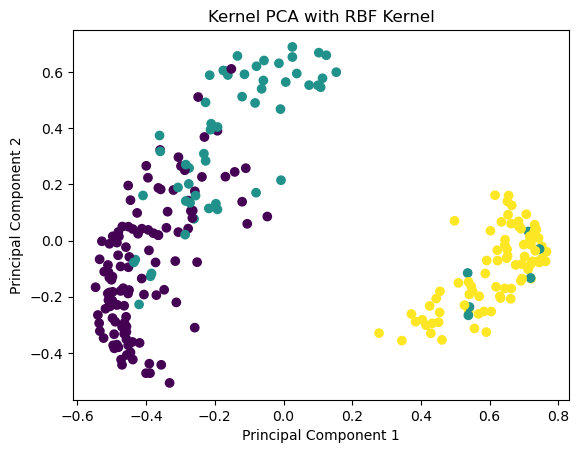

In [7]:
from sklearn.decomposition import KernelPCA

# Apply Kernel PCA with RBF kernel
kpca = KernelPCA(n_components=2, kernel='rbf', gamma=0.1)
X_kpca = kpca.fit_transform(X_train)

# Plot the reduced data
plt.scatter(X_kpca[:, 0], X_kpca[:, 1], c=y_train)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Kernel PCA with RBF Kernel')
plt.show()


# 2. Machine Learning Algorithms: Clustering

## Unsupervised Algorithms

> find patterns in $XX$ **without supervision from a target $yy$**

<img src="../imgs/ML_approaches.jpg" alt="Description" style="width: 1400px;"/>

## Dimentionality Reduction
- PCA see more [PCA](../Dive_deeper/PCA.ipynb) and [PCA_interactive](../Dive_deeper/PCA.html)
- UMAP
- t-SNE
- ...

### PCA example in Fluid mechanic


<img src="../imgs/flow_original.gif" width="800" alt="Bigger GIF">


<img src="../imgs/pcas.jpg" alt="Description" style="width: 1400px;"/>

<img src="../imgs/pca_reconst.jpg" alt="Description" style="width: 600px;"/>

<img src="../imgs/pca.gif" width="800" alt="Bigger GIF">


UMAP (Uniform Manifold Approximation and Projection) and t-SNE (t-distributed Stochastic Neighbor Embedding) are powerful unsupervised learning techniques that can be used for both:

- Dimensionality reduction: Similar to PCA, these methods reduce the number of features (dimensions) while preserving essential structures and patterns in the data.
- Visualization: These methods are particularly useful for visualizing high-dimensional data in 2D or 3D, providing an intuitive understanding of how the data is structured and clustered.


Both UMAP and t-SNE are manifold learning techniques, which means they try to understand and represent how data is distributed on a lower-dimensional manifold within a higher-dimensional space. They attempt to retain the relationships between points when projecting data into lower dimensions. However, they go beyond PCA, as PCA focuses on maximizing variance, while these methods emphasize local structure.



## Main Differences between t-SNE and UMAP

#### t-SNE (t-distributed Stochastic Neighbor Embedding)
t-SNE represents high-dimensional neighbourhood similarities as probabilities and minimises $KL(P\|Q)$ between those similarities and an embedding.

- Gaussian conditional similarities in the input; a **Student's t distribution** in the low-dimensional embedding.
- Euclidean distance is the default, but other metrics and precomputed distances are supported.
- Emphasises local neighbourhoods. A visually separated group is not by itself evidence of a distinct population.

#### UMAP (Uniform Manifold Approximation and Projection)
UMAP builds a weighted neighbourhood graph and optimises a low-dimensional representation of that graph.

- Supports different input distance metrics.
- Often runs faster on large datasets, although runtime depends on implementation and settings.
- Both methods distort some distances; neither guarantees faithful global geometry.

**Key hyperparameter for t-SNE: perplexity**

Perplexity is an entropy-based effective number of neighbours, not a distance threshold. Increasing it asks the algorithm to consider broader neighbourhoods when constructing input similarities.

A common starting range is 5–50; it must be smaller than the number of observations. Compare several choices before interpreting the plot.

**Key hyperparameters for UMAP:**
* `n_neighbors`: determines the size of the local neighborhood that UMAP uses for constructing the manifold. It controls the balance between local and global structure.

  ** Typical Range: 5 to 50.


* `min_dist` controls how tightly UMAP packs the points in the low-dimensional space.

  ** Typical Range: 0.001 to 0.5.


## The bellow links are amazing giving you some ideas on how changing hyperparameters affects:

- [t-SNE](https://distill.pub/2016/misread-tsne/)
- [UMAP](https://pair-code.github.io/understanding-umap/)

## How to (mis)read UMAP and t-SNE

* Hyperparameters really matter 
* Cluster sizes in a t-SNE plot mean nothing (because t-SNE preserves local structure over global structure: large clusters of data tend to be expanded)
* Distances between clusters might not mean anything
* Random noise doesn’t always look random
* For topology, you may need more than one plot

## Clustering

Clustering is an unsupervised learning technique that groups similar data points together into clusters. Unlike classification, clustering doesn't rely on labeled data. 

- Based on the way they group data points: density-based and distance-based methods:
  - Distance-Based: distance (often Euclidean distance or other metrics) between data points to form clusters. Data points that are closer to each other in the feature space are grouped together, while points that are farther apart are assigned to different clusters
    - Commonly used method: K-Means
  - Density-Based: group data points based on connected dense neighbourhoods defined using a distance metric and neighbourhood radius.
    - Commonly used method: DBSCAN

## K-Means Clustering
K-Means is one of the most commonly used clustering algorithms. It partitions the dataset into K clusters, where each cluster is represented by the mean (centroid) of the points in the cluster.


1. **Initialise**: Choose K centres; scikit-learn uses k-means++ by default.
2. **Assign**: Assign each point to its nearest centre.
3. **Update**: Replace each centre by the mean of its assigned points.
4. **Repeat** until the stopping criterion is reached. Different initial centres can lead to different local optima.
5. **Predict**: Assign a new point to its nearest fitted centre. These are cluster identifiers, not supervised class labels.

## Key Parameters
- **K**: number of clusters.
- **n_init**: number of initialisations; keep the run with the lowest inertia.
- **max_iter**: maximum number of iterations per run.

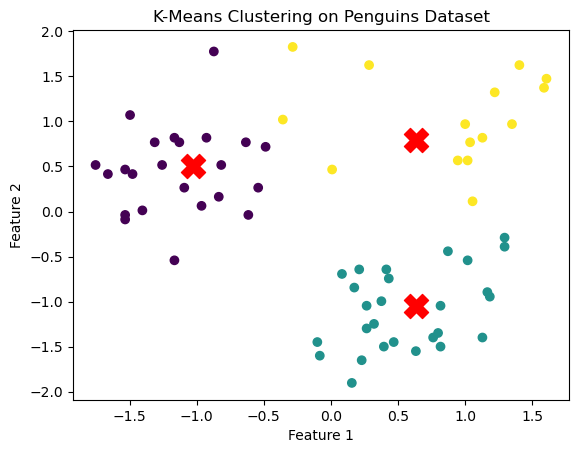

In [8]:
from sklearn.cluster import KMeans

penguin_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
penguin_kmeans.fit(X_train)

y_kmeans = penguin_kmeans.predict(X_test)

plt.scatter(X_test.iloc[:, 0], X_test.iloc[:, 1], c=y_kmeans, cmap='viridis')
plt.scatter(penguin_kmeans.cluster_centers_[:, 0], penguin_kmeans.cluster_centers_[:, 1], s=300, c='red', marker='X')
plt.title('K-Means Clustering on Penguins Dataset')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

- Elbow Method: plots the inertia (sum of squared distances from each point to its assigned centroid) for different values of K.

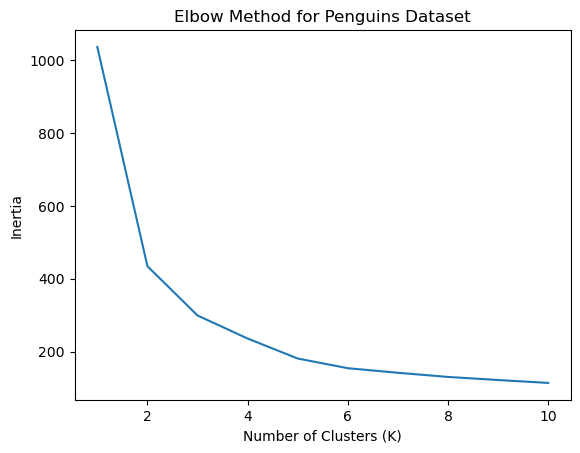

In [9]:
inertia = []
for k in range(1, 11):
    candidate_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    candidate_kmeans.fit(X_train)
    inertia.append(candidate_kmeans.inertia_)

# Plot inertia
plt.plot(range(1, 11), inertia)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Penguins Dataset')
plt.show()

- Silhouette Score: measures how similar each point is to its own cluster compared to other clusters. A higher silhouette score indicates better clustering.


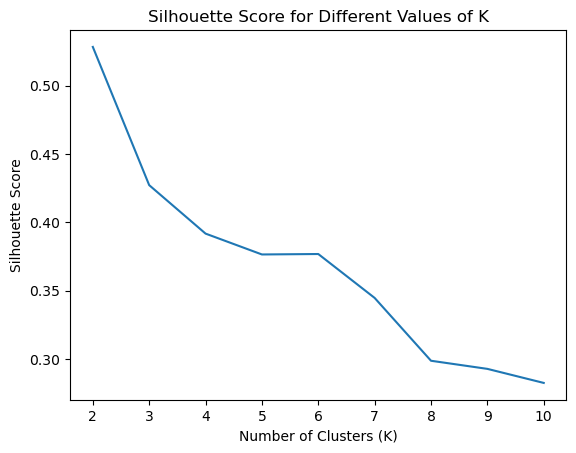

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []

for k in range(2, 11):
    candidate_kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    candidate_kmeans.fit(X_train)
    cluster_labels = candidate_kmeans.predict(X_train)
    score = silhouette_score(X_train, cluster_labels)
    silhouette_scores.append(score)

# Plot the Silhouette Score for each K
plt.plot(range(2, 11), silhouette_scores)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different Values of K')
plt.show()

## DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN connects dense neighbourhoods and can recover non-convex groups.

- **Core:** at least `min_samples` observations within distance $\varepsilon$, including the point itself.
- **Border:** within $\varepsilon$ of a core point, but not itself core.
- **Noise:** not density-reachable from a core point; labelled `-1`.

The distance metric and feature scales matter. One global radius can struggle when clusters have very different densities. A border point reachable from two clusters may depend on traversal order.

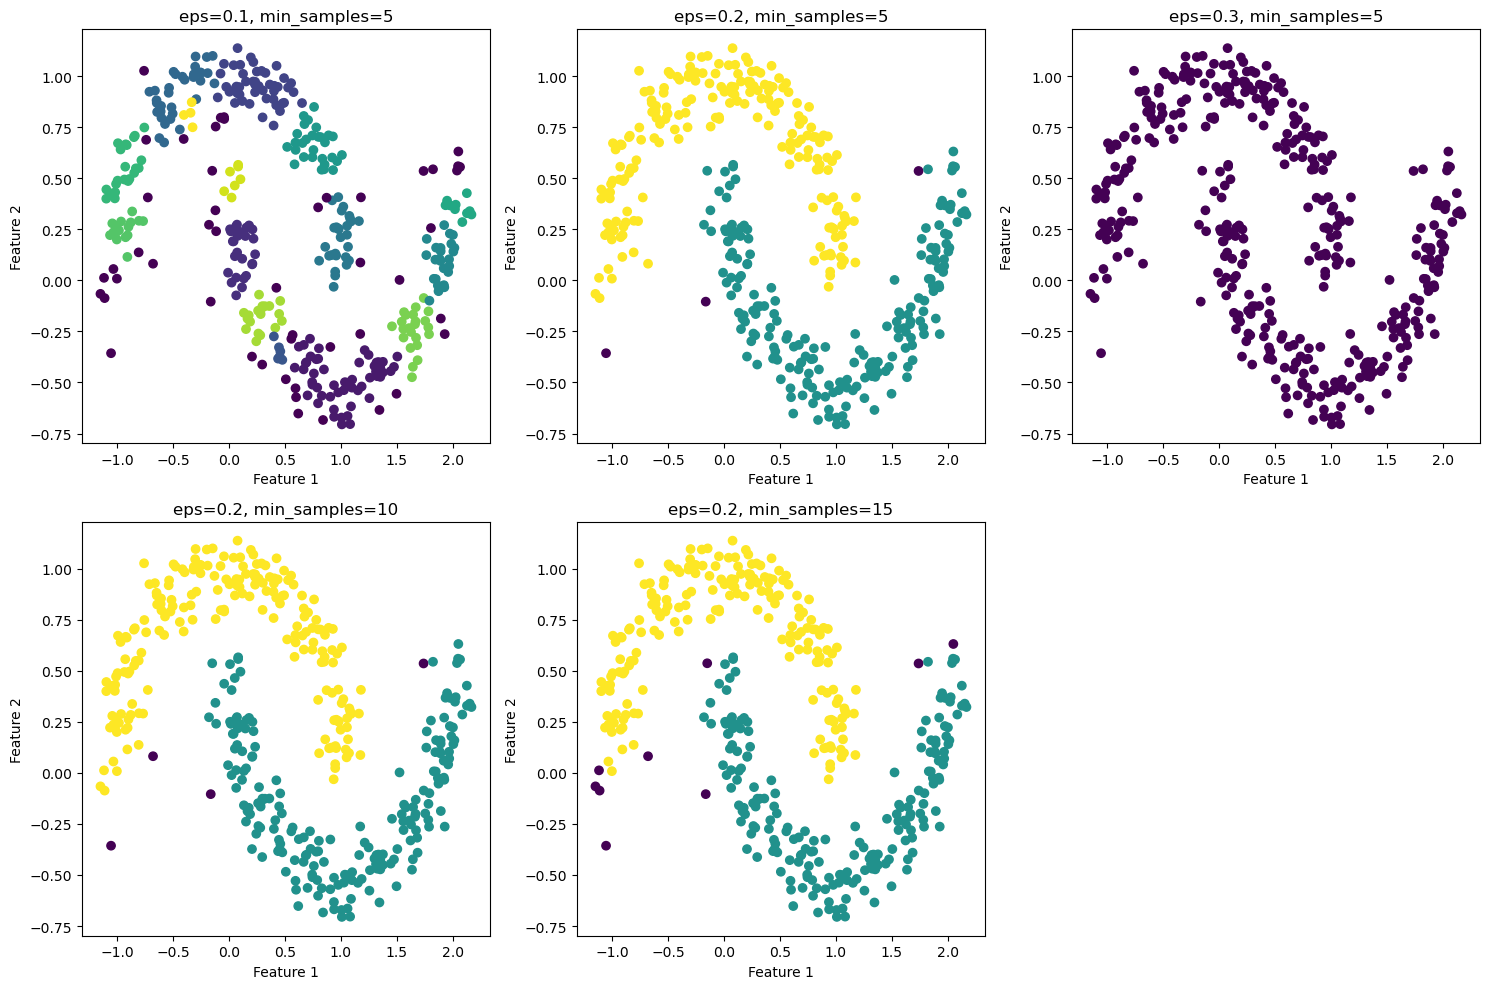

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X, _ = make_moons(n_samples=400, noise=0.1, random_state=42)

params = [
    {'eps': 0.1, 'min_samples': 5},
    {'eps': 0.2, 'min_samples': 5},
    {'eps': 0.3, 'min_samples': 5},
    {'eps': 0.2, 'min_samples': 10},
    {'eps': 0.2, 'min_samples': 15}
]

plt.figure(figsize=(15, 10))
for i, param in enumerate(params):
    dbscan = DBSCAN(eps=param['eps'], min_samples=param['min_samples'])
    labels = dbscan.fit_predict(X)
    
    plt.subplot(2, 3, i + 1)
    plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', marker='o')
    plt.title(f"eps={param['eps']}, min_samples={param['min_samples']}")
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')

plt.tight_layout()
plt.show()


DBSCAN assigned 397/400 observations.
Scores use different subsets if noise is present; inspect the plots too.


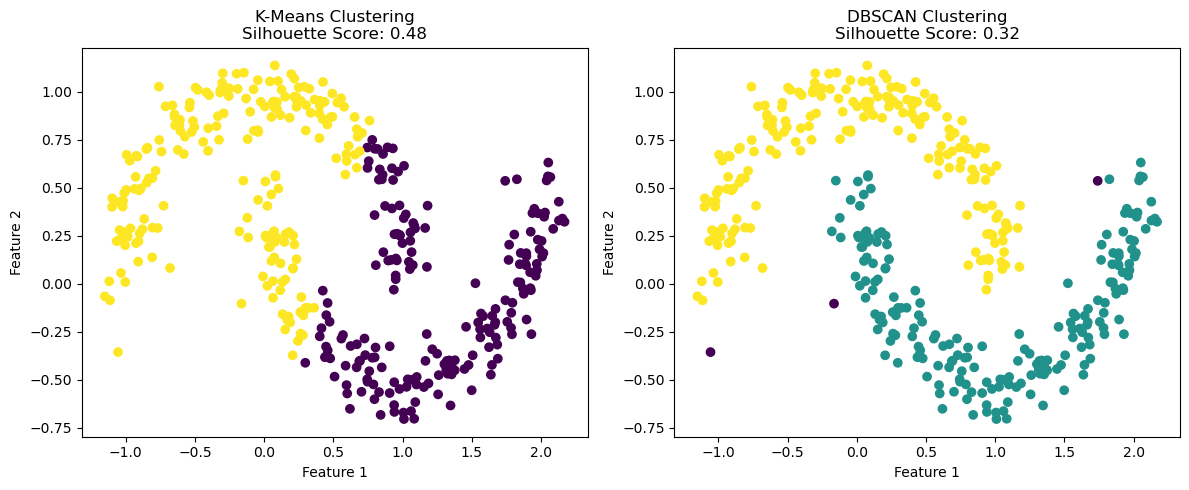

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# Apply K-Means
moons_kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_labels = moons_kmeans.fit_predict(X)
kmeans_silhouette = silhouette_score(X, kmeans_labels)

# Apply DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5)
dbscan_labels = dbscan.fit_predict(X)
# Exclude noise: this evaluates only the observations DBSCAN assigned.
assigned = dbscan_labels != -1
n_clusters = len(np.unique(dbscan_labels[assigned]))
dbscan_silhouette = np.nan
if 2 <= n_clusters < assigned.sum():
    dbscan_silhouette = silhouette_score(X[assigned], dbscan_labels[assigned])
print(f'DBSCAN assigned {assigned.sum()}/{len(X)} observations.')
print('Scores use different subsets if noise is present; inspect the plots too.')

# Plot K-Means results
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', marker='o')
plt.title(f'K-Means Clustering\nSilhouette Score: {kmeans_silhouette:.2f}')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

# Plot DBSCAN results
plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=dbscan_labels, cmap='viridis', marker='o')
plt.title(f'DBSCAN Clustering\nSilhouette Score: {dbscan_silhouette:.2f}')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.tight_layout()
plt.show()

# 3. Model Selection and Evaluation: Model Selection and Evaluation for Unsupervised Learning


- In unsupervised learning, we rely on internal metrics such as [**Silhouette Score**](https://scikit-learn.org/1.5/auto_examples/cluster/plot_kmeans_silhouette_analysis.html), **Davies-Bouldin Index**, and **Inertia** (for K-Means) to evaluate clustering performance.


In [13]:
from sklearn.metrics import silhouette_score

silhouette = silhouette_score(X_test, y_kmeans)
print(f'Silhouette Score for K-Means: {silhouette}')


Silhouette Score for K-Means: 0.5453408310965904


In [14]:
from sklearn.metrics import davies_bouldin_score

db_score = davies_bouldin_score(X_test, y_kmeans)
print(f'Davies-Bouldin Index for K-Means: {db_score}')


Davies-Bouldin Index for K-Means: 0.6936377959405594


In [15]:
print(f'Penguin training inertia (K=3): {penguin_kmeans.inertia_}')

Penguin training inertia (K=3): 299.2334866868144


- If true labels are available, external metrics like Adjusted Rand Index (ARI) and Adjusted Mutual Information (AMI) can be used to compare the predicted clusters to the actual labels.

In [16]:
from sklearn.metrics import adjusted_mutual_info_score

ami_kmeans = adjusted_mutual_info_score(y_test, y_kmeans)
print(f'Adjusted Mutual Information for K-Means: {ami_kmeans}')


Adjusted Mutual Information for K-Means: 0.8272620329332413


- PCA can be combined with clustering. Compare candidate partitions in a clearly specified feature space. Inertia and distance-based scores computed before and after a change of scale or dimension are not directly comparable as if the geometry were unchanged.
- Check stability, domain meaning and sensitivity to preprocessing alongside an internal score.